# Karate Club Modularity: A Study

In this assignment, we aim to divide the karate club into communities by Newman's spectral modularity method, with the final conclusion suggesting the split of the club into two after the argument.

Initially, the community splits into two (the real split), and then further into five after four splits. After every split we draw the partition and recompute degree, betweenness, closeness and clustering for every node inside its community, and study how these evolve.

## 1. Initial Method:

With adjacency matrix $A$, degree vector $k$ and $m$ edges, the **modularity matrix** is
$$B = A - \frac{k k^{\top}}{2m}, \qquad B_{ij} = A_{ij} - \frac{k_i k_j}{2m},$$

where $k_ik_j/2m$ is the expected number of edges between $i$ and $j$ in the random model. A split into two groups is encoded by $s\in\{-1,+1\}^n$ and scored by:

$$Q = \frac{1}{4m}\, s^{\top} B\, s .$$

Instead of forcing $s_i \in \{-1, +1\}$, suppose we allow $s_i$ to take any real value, but constrain $\|s\|_2 = 1$. Then the problem becomes:

$$\max_{\|s\|_2=1} s^{\top}B s.$$

This expression is a quadratic form, and by the Rayleigh–Ritz theorem, the maximizer is the eigenvector corresponding to the largest eigenvalue of $B$, called the leading eigenvector $u_1$. We map these continuous values back to $\pm1$ by taking their signs: $s_i=+1$ if $(u_1)_i>0$, else $-1$.


### 2. Initial Data and Modularity matrix $B$:

In [ ]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

Initializing network, maps the node indices to start from 1, and creates the custom modularity matrix $B$:

In [ ]:
# Load the Karate Club graph (comes with NetworkX)
G = nx.karate_club_graph()
G = nx.relabel_nodes(G, {i: i + 1 for i in G.nodes})   # use node numbers 1..34 like Zachary's paper
nodes = sorted(G.nodes)
n = G.number_of_nodes()
m = G.number_of_edges()
print("nodes:", n, " edges:", m)

# Adjacency matrix A (plain 0/1: weight=None ignores the edge weights stored in the graph)
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)

# Degree vector k and modularity matrix B = A - k k^T / (2m)
k = A.sum(axis=1)
B = A - np.outer(k, k) / (2 * m)

# One fixed layout, used for all the pictures
pos = nx.spring_layout(G, seed=42)

We check if $B$ is symmetric, and then find the eigenvalues of it:

In [ ]:
# Quick sanity checks from the handout
print("B is symmetric:", np.allclose(B, B.T))
print("B times all-ones vector is 0:", np.allclose(B @ np.ones(n), 0))
print("largest eigenvalue of B:", round(np.linalg.eigvalsh(B)[-1], 4))

B is symmetric: True
B times all-ones vector is 0: True
largest eigenvalue of B: 4.9771


$B$ is symmetric, $B\mathbf 1=0$ (so the trivial one-community partition has $Q=0$), and the largest eigenvalue is $\lambda_1\approx4.98>0$, so the club *can* be split.

### 3. Recursive Bisection:

This code implements community detection from scratch by using the leading eigenvector of the modularity matrix to bisect the graph. It repeatedly splits communities with positive eigenvalues, keeping track of each iteration's partition, and computes the modularity $Q$ until no further splits can improve the metric:

In [ ]:
def modularity(partition):
    """Q = (1/2m) * (sum of B_ij over all pairs i, j that are in the same community)."""
    Q = 0
    for group in partition:
        idx = [v - 1 for v in group]          # node v is row/column v-1 of the matrix
        Q = Q + B[np.ix_(idx, idx)].sum()
    return round(Q / (2 * m), 10) + 0.0     # rounding avoids printing -0.0000


partition = [nodes]        # current communities: at the start, everybody is in one community
partitions = [partition]   # partitions[t] = communities after t splits
lambdas = []               # leading eigenvalue that caused each split
to_check = [nodes]         # communities that still have to be tested

while len(to_check) > 0:
    group = to_check.pop(0)                   # take the next community

    # restricted modularity matrix B^(C): rows/columns of the nodes in this community
    idx = [v - 1 for v in group]
    B_C = B[np.ix_(idx, idx)]

    # leading eigenvalue and eigenvector (eigh sorts eigenvalues from small to large)
    values, vectors = np.linalg.eigh(B_C)
    lam = values[-1]
    u = vectors[:, -1]
    if u[np.argmax(abs(u))] < 0:              # an eigenvector can be flipped (u or -u);
        u = -u

    # split by the sign of the eigenvector entries
    plus = [group[i] for i in range(len(group)) if u[i] > 0]
    minus = [group[i] for i in range(len(group)) if u[i] <= 0]

    # stop if no split can improve modularity
    if lam <= 1e-9 or len(plus) == 0 or len(minus) == 0:
        print(f"community of size {len(group):2d}: lambda1 = {lam:7.4f} -> stop")
        continue

    # replace the community by "plus" (same place) and add "minus" at the end
    new_partition = []
    for g in partition:
        if g == group:
            new_partition.append(plus)
        else:
            new_partition.append(g)
    new_partition.append(minus)

    partition = new_partition
    partitions.append(partition)
    lambdas.append(lam)
    to_check.append(plus)
    to_check.append(minus)
    print(f"community of size {len(group):2d}: lambda1 = {lam:7.4f} -> split into {len(plus)} + {len(minus)}"
          f"   (split number {len(partitions) - 1}, Q = {modularity(partition):.4f})")

community of size 34: lambda1 =  4.9771 -> split into 16 + 18   (split number 1, Q = 0.3715)
community of size 16: lambda1 =  2.9441 -> split into 10 + 6   (split number 2, Q = 0.3898)
community of size 18: lambda1 =  2.5041 -> split into 13 + 5   (split number 3, Q = 0.4081)
community of size 10: lambda1 =  2.5712 -> stop
community of size  6: lambda1 =  2.1480 -> split into 5 + 1   (split number 4, Q = 0.4094)
community of size 13: lambda1 =  2.3563 -> stop
community of size  5: lambda1 =  1.8759 -> stop
community of size  5: lambda1 =  2.1470 -> stop
community of size  1: lambda1 = -0.0064 -> stop


In [ ]:
print("Q after each iteration:")
for t in range(len(partitions)):
    print(f"  iteration {t}: {len(partitions[t])} communities, Q = {modularity(partitions[t]):.4f}")

print("\nFinal communities:")
for group in partitions[-1]:
    print("  ", sorted(group))

# Cross-check our Q against NetworkX's own function
final_sets = [set(g) for g in partitions[-1]]
print("\nQ from NetworkX:", round(nx.community.modularity(G, final_sets, weight=None), 4))

Q after each iteration:
  iteration 0: 1 communities, Q = 0.0000
  iteration 1: 2 communities, Q = 0.3715
  iteration 2: 3 communities, Q = 0.3898
  iteration 3: 4 communities, Q = 0.4081
  iteration 4: 5 communities, Q = 0.4094

Final communities:
   [1, 2, 3, 4, 8, 13, 14, 18, 20, 22]
   [9, 10, 15, 16, 19, 21, 23, 24, 27, 30, 31, 33, 34]
   [5, 6, 7, 11, 17]
   [25, 26, 28, 29, 32]
   [12]

Q from NetworkX: 0.4094


Every split has a positive $\lambda_1$ and increases $Q$: the whole club splits first ($\lambda_1=4.98$), then both halves split again, and finally one 6-member group sheds node 12. After that every group has $\lambda_1\le0$ or gives no real two-sided split, so the recursion stops with 5 communities and $Q=0.4094$.

### 4. Visualisations:

We visualise the split by various graphs:

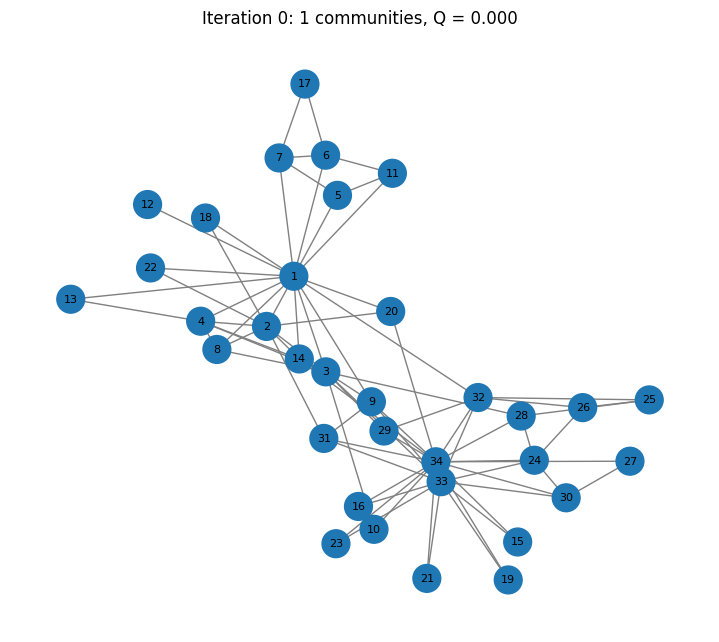

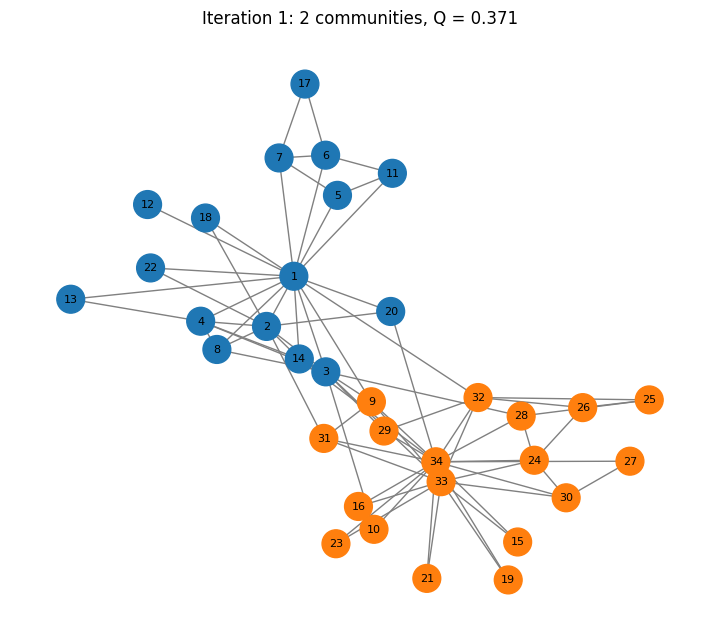

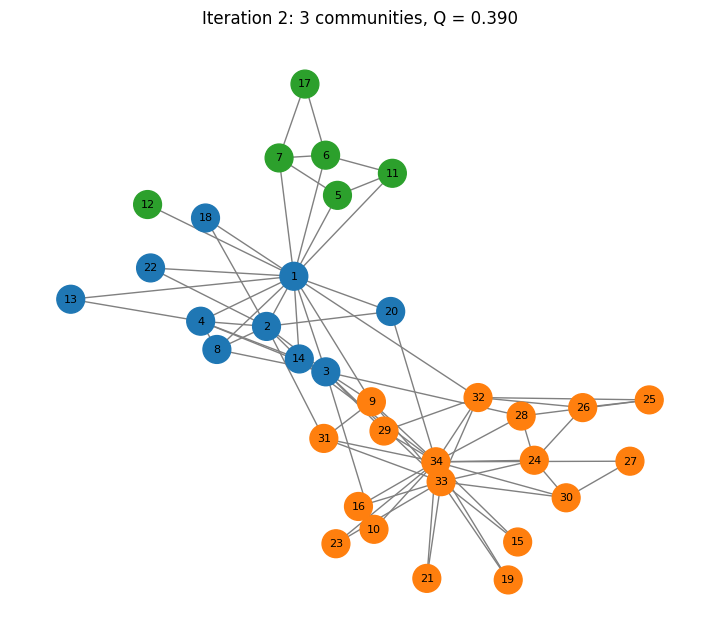

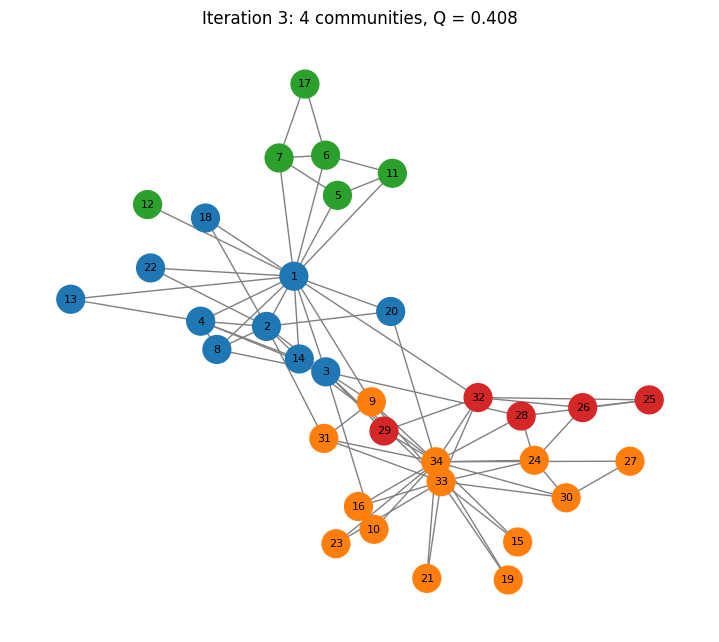

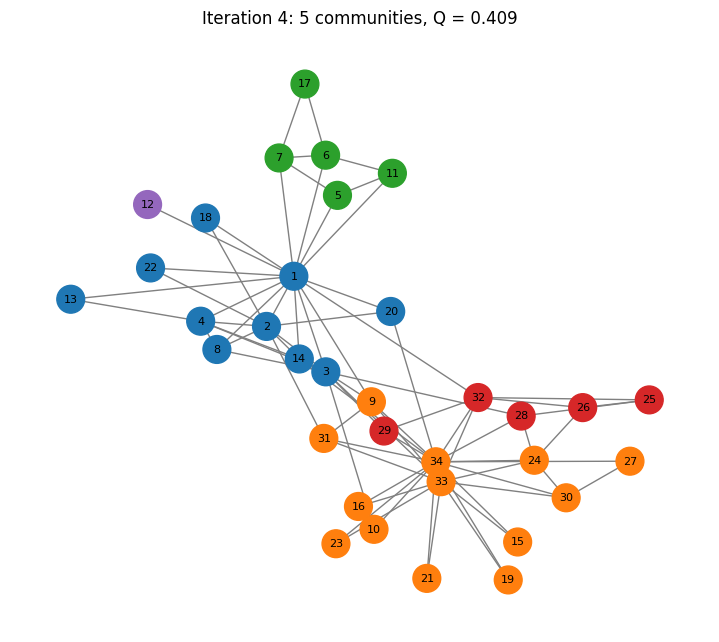

In [ ]:
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"]

for t in range(len(partitions)):
    # give every node the colour of its community
    color_of = {}
    for c in range(len(partitions[t])):
        for v in partitions[t][c]:
            color_of[v] = colors[c]

    plt.figure(figsize=(7, 6))
    nx.draw(G, pos, node_color=[color_of[v] for v in nodes], with_labels=True,
            node_size=400, font_size=8, edge_color="gray")
    plt.title(f"Iteration {t}: {len(partitions[t])} communities, Q = {modularity(partitions[t]):.3f}")
    plt.show()

* **Iteration 1** (16 + 18) already matches the real split except for one node.
* **Iterations 2–3** split each faction again: Mr. Hi's side into $\{1,2,3,4,8,13,14,18,20,22\}$ and $\{5,6,7,11,12,17\}$ (attached to the rest mostly through node 1), and the Officer's side into the large core $\{9,10,15,16,19,21,23,24,27,30,31,33,34\}$ around hubs 33 and 34 and the cluster $\{25,26,28,29,32\}$.
* **Iteration 4** removes the pendant node 12 (one neighbour only, node 1) from its group. It is the weakest split (gain 0.0013) and creates a one-node community.

### Node metrics after every split

Computed on the *whole* graph the metrics would never change, so after each split we compute them **inside each node's own community** (the subgraph of that community), using degree centrality, betweenness centrality, closeness centrality and clustering from NetworkX. Iteration 0 is the ordinary whole-graph value.

### Metric Definitions & Formulas

To understand how roles evolve as communities split, we compute four standard centrality and cohesion measures using NetworkX:

1. **Degree Centrality**  
   $$C_D(i) = \frac{k_i}{n - 1}$$
 Measures the fraction of nodes directly connected to $i$. High values identify immediate local hubs.

2. **Betweenness Centrality**  
   $$C_B(i) = \sum_{s \neq i \neq t} \frac{\sigma_{st}(i)}{\sigma_{st}}$$
Calculates how often node $i$ lies on the shortest paths between other nodes, indicating a bridge or broker role.

3. **Closeness Centrality**  
   $$C_C(i) = \frac{n - 1}{\sum_{j \neq i} d(i, j)}$$
The reciprocal of the sum of the shortest path distances from $i$ to all other nodes. High scores denote efficient spreaders.

4. **Clustering Coefficient**  
   $$C(i) = \frac{2 T(i)}{k_i(k_i - 1)}$$
 The fraction of a node's neighbors that are also connected to each other, indicating integration in tightly-knit local cliques.

In [ ]:
metric_names = ["Degree centrality", "Betweenness centrality", "Closeness centrality", "Clustering coefficient"]

# metrics_by_iter[t][metric name][node] = value   (t = iteration number)
metrics_by_iter = {}

for t in range(len(partitions)):
    degree, between, close, cluster = {}, {}, {}, {}

    for group in partitions[t]:
        H = G.subgraph(group)                         # the graph of this community only
        if len(group) == 1:                           # a single node: metrics are meaningless
            for v in group:
                degree[v] = between[v] = close[v] = cluster[v] = np.nan
        else:
            degree.update(nx.degree_centrality(H))
            between.update(nx.betweenness_centrality(H))
            close.update(nx.closeness_centrality(H))
            cluster.update(nx.clustering(H))

    metrics_by_iter[t] = {"Degree centrality": degree, "Betweenness centrality": between,
                          "Closeness centrality": close, "Clustering coefficient": cluster}

iterations = list(metrics_by_iter.keys())

# Construct a beautifully formatted table for all 34 nodes at the final iteration
last_iter = iterations[-1]
metrics_df = pd.DataFrame({
    "Community ID": [next(i for i, group in enumerate(partitions[last_iter]) if node in group) for node in nodes],
    "Degree Centrality": [metrics_by_iter[last_iter]["Degree centrality"][node] for node in nodes],
    "Betweenness Centrality": [metrics_by_iter[last_iter]["Betweenness centrality"][node] for node in nodes],
    "Closeness Centrality": [metrics_by_iter[last_iter]["Closeness centrality"][node] for node in nodes],
    "Clustering Coefficient": [metrics_by_iter[last_iter]["Clustering coefficient"][node] for node in nodes]
}, index=pd.Index(nodes, name="Node"))

print(f"--- Node Metrics Inside Final Communities (Iteration {last_iter}) ---")
display(metrics_df.round(4))

--- Node Metrics Inside Final Communities (Iteration 4) ---


,Community ID,Degree Centrality,Betweenness Centrality,Closeness Centrality,Clustering Coefficient
Node,,,,,
1,0,1.0000,0.3542,1.0000,0.3611
2,0,0.8889,0.2153,0.9000,0.4286
3,0,0.5556,0.0069,0.6923,0.9000
4,0,0.6667,0.0625,0.7500,0.6667
5,2,0.5000,0.0833,0.6667,0.0000
6,2,0.7500,0.2500,0.8000,0.3333
7,2,0.7500,0.2500,0.8000,0.3333
8,0,0.4444,0.0000,0.6429,1.0000
9,1,0.2500,0.0000,0.5714,1.0000


### Evolution of each metric
Every grey line is one node; the five nodes with the highest average value are coloured.

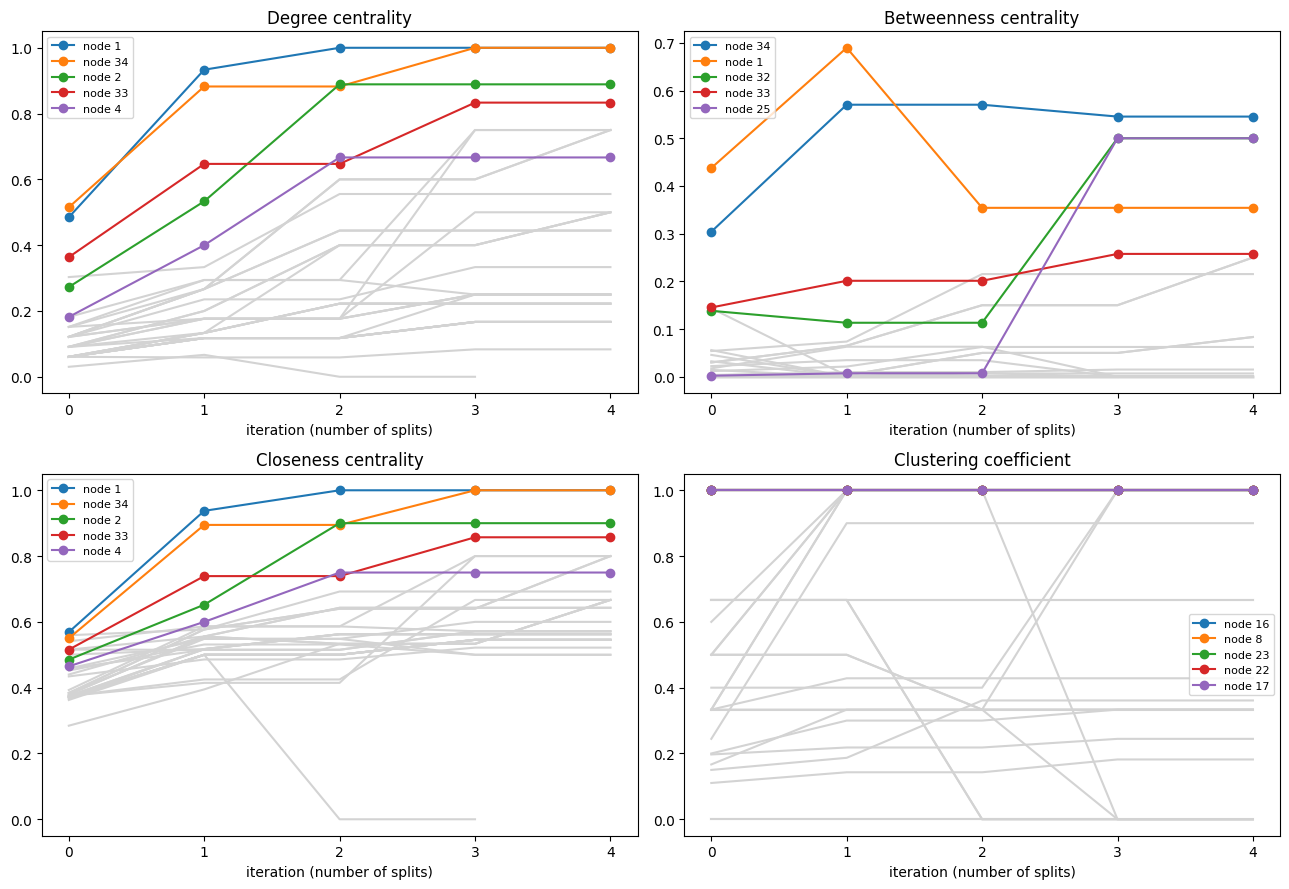

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, name in zip(axes.flatten(), metric_names):
    # table: one row per node, one column per iteration
    table = pd.DataFrame({t: metrics_by_iter[t][name] for t in iterations}).sort_index()

    top5 = table.mean(axis=1).sort_values(ascending=False).index[:5]   # nodes with highest average value

    for v in table.index:                         # all other nodes in light grey
        if v not in top5:
            ax.plot(iterations, table.loc[v], color="lightgray")
    for v in top5:                                # the 5 highest nodes in colour
        ax.plot(iterations, table.loc[v], marker="o", label=f"node {v}")

    ax.set_title(name)
    ax.set_xlabel("iteration (number of splits)")
    ax.set_xticks(iterations)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Modularity after each split:

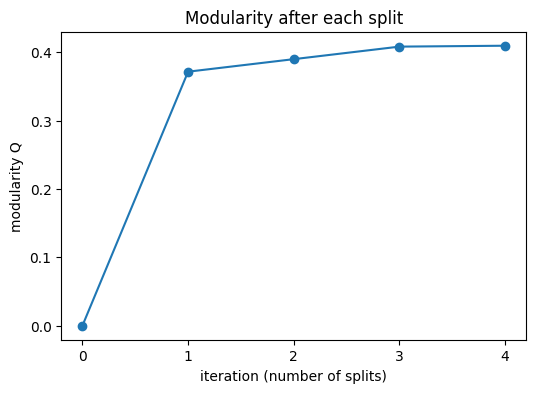

In [ ]:
Q_values = [modularity(p) for p in partitions]

plt.figure(figsize=(6, 4))
plt.plot(range(len(Q_values)), Q_values, "o-")
plt.xlabel("iteration (number of splits)")
plt.ylabel("modularity Q")
plt.title("Modularity after each split")
plt.xticks(range(len(Q_values)))
plt.show()

### 5. Centrality of Nodes:

In [ ]:
for name in metric_names:
    table = pd.DataFrame({t: metrics_by_iter[t][name] for t in iterations}).sort_index()

    always = set(table.index)
    print(name)
    for t in iterations:
        top5 = set(table[t].dropna().sort_values(ascending=False).index[:5])
        print(f"   iteration {t}: top 5 = {sorted(top5)}")
        always = always & top5
    print("   in the top 5 at every iteration:", sorted(always), "\n")

# How much does the ranking change between iteration 0 and the last iteration?
print("Spearman rank correlation, iteration 0 vs last iteration")
for name in metric_names:
    table = pd.DataFrame({t: metrics_by_iter[t][name] for t in iterations}).dropna()
    print(f"   {name:24s} {table[0].corr(table[iterations[-1]], method='spearman'):.3f}")

Degree centrality
   iteration 0: top 5 = [1, 2, 3, 33, 34]
   iteration 1: top 5 = [1, 2, 4, 33, 34]
   iteration 2: top 5 = [1, 2, 4, 33, 34]
   iteration 3: top 5 = [1, 2, 32, 33, 34]
   iteration 4: top 5 = [1, 2, 6, 33, 34]
   in the top 5 at every iteration: [1, 2, 33, 34] 

Betweenness centrality
   iteration 0: top 5 = [1, 3, 32, 33, 34]
   iteration 1: top 5 = [1, 2, 32, 33, 34]
   iteration 2: top 5 = [1, 2, 6, 33, 34]
   iteration 3: top 5 = [1, 25, 32, 33, 34]
   iteration 4: top 5 = [1, 25, 32, 33, 34]
   in the top 5 at every iteration: [1, 33, 34] 

Closeness centrality
   iteration 0: top 5 = [1, 3, 14, 32, 34]
   iteration 1: top 5 = [1, 2, 4, 33, 34]
   iteration 2: top 5 = [1, 2, 4, 33, 34]
   iteration 3: top 5 = [1, 2, 32, 33, 34]
   iteration 4: top 5 = [1, 2, 6, 33, 34]
   in the top 5 at every iteration: [1, 34] 

Clustering coefficient
   iteration 0: top 5 = [8, 16, 17, 22, 23]
   iteration 1: top 5 = [8, 9, 18, 27, 29]
   iteration 2: top 5 = [8, 9, 18, 27, 2

A short discussion on centrality:

1. We observe that two major nodes (1 and 34) consistently rank in the top 5 of degree centrality, betweenness centrality and closeness centrality. This is because these are the major hubs from which the real split takes place (Mr. Hi and the Officer) and remain strong both globally and in their sub communities.

2. We also find that as the communities get split more and more, the local metrics we apply (degree and closeness) increases. This is due to the smaller community sizes acting as the normalization denominator. This could sometimes isolate border nodes and skew results in the metrics.

### 6. Does the method recover the real split?

In [ ]:
for group in partitions[1]:
    if 1 in group:                       # node 1 is Mr. Hi
        hi_side = group

wrong = []
for v in nodes:
    in_hi_side = v in hi_side
    really_hi = G.nodes[v]["club"] == "Mr. Hi"
    if in_hi_side != really_hi:
        wrong.append(v)

print("First split puts", len(hi_side), "members on Mr. Hi's side")
print("Correctly placed:", n - len(wrong), "of", n, " -> wrongly placed nodes:", wrong)

# Modularity of the real split, for comparison
real_split = [[v for v in nodes if G.nodes[v]["club"] == "Mr. Hi"],
              [v for v in nodes if G.nodes[v]["club"] == "Officer"]]
print("Q of the real split         :", round(modularity(real_split), 4))
print("Q of our first split        :", round(modularity(partitions[1]), 4))
print("Q of our final partition    :", round(modularity(partitions[-1]), 4))

First split puts 16 members on Mr. Hi's side
Correctly placed: 33 of 34  -> wrongly placed nodes: [9]
Q of the real split         : 0.3582
Q of our first split        : 0.3715
Q of our final partition    : 0.4094


## References
1. Zachary, W. W. (1977). *An information flow model for conflict and fission in small groups.* Journal of Anthropological Research, 33(4), 452–473.
2. Newman, M. E. J. (2006). *Modularity and community structure in networks.* PNAS, 103(23), 8577–8582.
3. Hagberg, A., Schult, D., Swart, P. (2008). *Exploring network structure, dynamics, and function using NetworkX.* SciPy 2008.

## Credits

All code is written by Anthropic's Claude AI.